In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C6"
DTYPE="HRLK"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C6_10,29,"[DATA/TRAINING/C6/C6_10/IMG_7602.HEIC, DATA/TR..."
1,C6_11,29,"[DATA/TRAINING/C6/C6_11/IMG_7781.HEIC, DATA/TR..."
2,C6_12,27,"[DATA/TRAINING/C6/C6_12/IMG_7852.HEIC, DATA/TR..."
3,C6_13,25,"[DATA/TRAINING/C6/C6_13/IMG_7910.HEIC, DATA/TR..."
4,C6_14,27,"[DATA/TRAINING/C6/C6_14/IMG_7972.HEIC, DATA/TR..."
5,C6_15,25,"[DATA/TRAINING/C6/C6_15/IMG_8039_edited.jpg, D..."
6,C6_16,25,"[DATA/TRAINING/C6/C6_16/IMG_810 .HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_81359.HEIC')

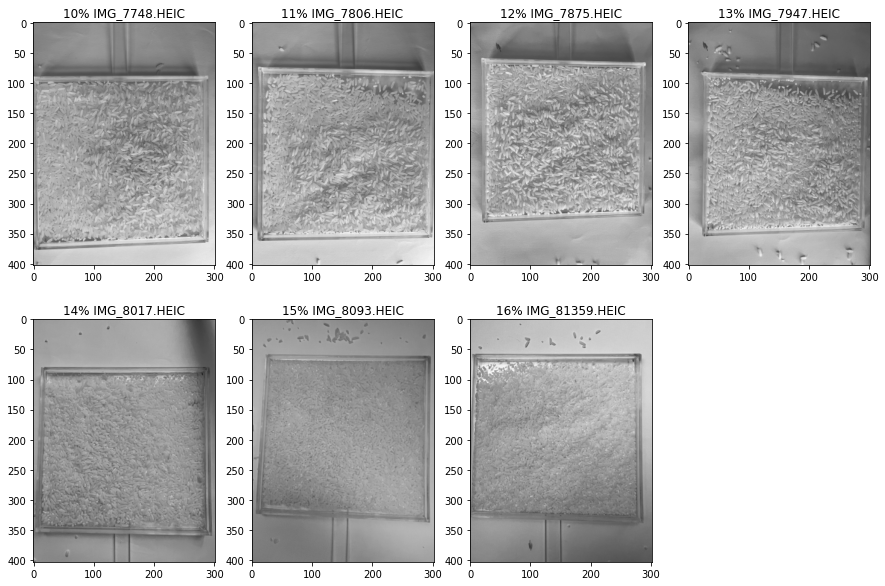

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [152]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [153]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.000663,88.341634,0.944872,801.244600,0.275898,323.183829,3116.636767,7.794081,11.415004,0.000432,...,0.000347,4.083853,-0.278150,0.988650,25,1008,756,3,IMG_7602.HEIC,10
1,0.000646,112.561576,0.932183,829.897149,0.272538,322.723026,3207.027020,7.799965,11.519613,0.000411,...,0.000331,4.198810,-0.265108,0.986500,25,1008,756,3,IMG_7605.HEIC,10
2,0.000687,116.840579,0.931570,853.717607,0.278174,322.629954,3298.029851,7.794167,11.509437,0.000410,...,0.000333,4.189551,-0.267778,0.986936,25,1008,756,3,IMG_7607.HEIC,10
3,0.000666,106.587981,0.934555,814.326512,0.287547,319.545124,3150.718065,7.799222,11.452541,0.000440,...,0.000346,4.154643,-0.269610,0.987285,25,1008,756,3,IMG_7610.HEIC,10
4,0.000542,103.057705,0.953384,1105.379340,0.280952,322.436334,4318.459654,8.006677,11.663334,0.000433,...,0.000354,4.133360,-0.294153,0.991939,25,1008,756,3,IMG_7613.HEIC,10
5,0.000626,107.246810,0.942055,925.418995,0.282195,335.398870,3594.429171,7.866520,11.533191,0.000423,...,0.000338,4.172295,-0.277426,0.988980,25,1008,756,3,IMG_7619.HEIC,10
6,0.000639,101.068923,0.937235,805.131561,0.285423,329.187145,3119.457323,7.797649,11.449704,0.000431,...,0.000349,4.127206,-0.275053,0.988174,25,1008,756,3,IMG_7621.HEIC,10
7,0.000604,111.348799,0.929270,787.141090,0.267488,324.306418,3037.215561,7.806193,11.565030,0.000404,...,0.000319,4.243054,-0.256509,0.984846,25,1008,756,3,IMG_7625.HEIC,10
8,0.000547,86.466199,0.961415,1120.457359,0.290785,328.392778,4395.363238,8.053691,11.588323,0.000456,...,0.000308,4.288805,-0.277078,0.989978,25,1008,756,3,IMG_7695.HEIC,10
9,0.000548,83.003412,0.961180,1069.083132,0.287983,321.986961,4193.329118,8.031338,11.566697,0.000455,...,0.000312,4.269445,-0.276987,0.989843,25,1008,756,3,IMG_7697.HEIC,10


# Classification

In [154]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [155]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [156]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [157]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [158]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [159]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.736842,0.775510,0.738095,0.756340,HRLK,C6,RF_C,25,1008,756,3
1,2,0.947368,0.964286,0.952381,0.958296,HRLK,C6,RF_C,25,1008,756,3
2,3,0.947368,0.964286,0.928571,0.946092,HRLK,C6,RF_C,25,1008,756,3
3,4,0.894737,0.916667,0.904762,0.910675,HRLK,C6,RF_C,25,1008,756,3
4,5,0.894737,0.928571,0.880952,0.904135,HRLK,C6,RF_C,25,1008,756,3
5,6,0.894737,0.928571,0.904762,0.916512,HRLK,C6,RF_C,25,1008,756,3
6,7,0.789474,0.847619,0.809524,0.828134,HRLK,C6,RF_C,25,1008,756,3
7,8,0.777778,0.823810,0.738095,0.778600,HRLK,C6,RF_C,25,1008,756,3
8,9,1.000000,1.000000,1.000000,1.000000,HRLK,C6,RF_C,25,1008,756,3
9,10,0.833333,0.833333,0.833333,0.833333,HRLK,C6,RF_C,25,1008,756,3


In [160]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C6,RF_C,0.871637,0.869048,0.883212,0.898265


### MLP Classifier

In [161]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [162]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [163]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.880952,0.857143,0.868885,HRLK,C6,MLP_C,25,1008,756,3
1,2,0.894737,0.942857,0.904762,0.923417,HRLK,C6,MLP_C,25,1008,756,3
2,3,0.947368,0.964286,0.952381,0.958296,HRLK,C6,MLP_C,25,1008,756,3
3,4,0.894737,0.928571,0.880952,0.904135,HRLK,C6,MLP_C,25,1008,756,3
4,5,0.894737,0.942857,0.880952,0.910854,HRLK,C6,MLP_C,25,1008,756,3
5,6,0.842105,0.869048,0.857143,0.863054,HRLK,C6,MLP_C,25,1008,756,3
6,7,0.947368,0.964286,0.928571,0.946092,HRLK,C6,MLP_C,25,1008,756,3
7,8,1.000000,1.000000,1.000000,1.000000,HRLK,C6,MLP_C,25,1008,756,3
8,9,0.944444,0.952381,0.952381,0.952381,HRLK,C6,MLP_C,25,1008,756,3
9,10,0.888889,0.928571,0.880952,0.904135,HRLK,C6,MLP_C,25,1008,756,3


In [164]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C6,MLP_C,0.909649,0.909524,0.923125,0.937381


### XGBoost Classifier

In [165]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [166]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.894737,0.928571,0.880952,0.904135,HRLK,C6,XGB_C,25,1008,756,3
1,2,0.894737,0.928571,0.880952,0.904135,HRLK,C6,XGB_C,25,1008,756,3
2,3,0.736842,0.870748,0.738095,0.798953,HRLK,C6,XGB_C,25,1008,756,3
3,4,0.736842,0.785714,0.738095,0.761161,HRLK,C6,XGB_C,25,1008,756,3
4,5,0.789474,0.845238,0.785714,0.814390,HRLK,C6,XGB_C,25,1008,756,3
5,6,0.894737,0.928571,0.880952,0.904135,HRLK,C6,XGB_C,25,1008,756,3
6,7,0.789474,0.738095,0.761905,0.749811,HRLK,C6,XGB_C,25,1008,756,3
7,8,0.944444,0.952381,0.952381,0.952381,HRLK,C6,XGB_C,25,1008,756,3
8,9,0.888889,0.904762,0.880952,0.892698,HRLK,C6,XGB_C,25,1008,756,3
9,10,0.888889,0.904762,0.904762,0.904762,HRLK,C6,XGB_C,25,1008,756,3


In [167]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C6,XGB_C,0.845906,0.840476,0.858656,0.878741


# External validation

In [168]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C6_10,5,"[DATA/TEST/C6/C6_10/IMG_7593.HEIC, DATA/TEST/C..."
1,C6_11,5,"[DATA/TEST/C6/C6_11/IMG_7772.HEIC, DATA/TEST/C..."
2,C6_12,5,"[DATA/TEST/C6/C6_12/IMG_7684.HEIC, DATA/TEST/C..."
3,C6_13,5,"[DATA/TEST/C6/C6_13/IMG_7919.HEIC, DATA/TEST/C..."
4,C6_14,5,"[DATA/TEST/C6/C6_14/IMG_7980.HEIC, DATA/TEST/C..."
5,C6_15,5,"[DATA/TEST/C6/C6_15/IMG_8049_edited.jpg, DATA/..."
6,C6_16,5,"[DATA/TEST/C6/C6_16/IMG_8105.HEIC, DATA/TEST/C..."


In [169]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [170]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [171]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.000621,108.785576,0.944607,981.936288,0.280207,316.740548,3818.959576,7.891064,11.588376,0.000419,...,0.000330,4.217098,-0.272140,0.988307,25,1008,756,3,IMG_7593.HEIC,10
1,0.000560,99.104729,0.954530,1089.775944,0.290599,327.343035,4259.999048,7.988915,11.626605,0.000446,...,0.000365,4.097441,-0.297148,0.992190,25,1008,756,3,IMG_7594.HEIC,10
2,0.000645,105.205889,0.940686,886.861034,0.284427,319.030994,3442.238246,7.841056,11.508634,0.000432,...,0.000342,4.177971,-0.271046,0.987798,25,1008,756,3,IMG_7597.HEIC,10
3,0.000539,103.831391,0.956810,1202.021283,0.285119,321.150074,4704.253739,8.044179,11.691304,0.000439,...,0.000351,4.148320,-0.295230,0.992230,25,1008,756,3,IMG_7599.HEIC,10
4,0.000692,113.630492,0.935096,875.368755,0.278948,319.390786,3387.844529,7.798663,11.498655,0.000421,...,0.000340,4.174353,-0.268360,0.987067,25,1008,756,3,IMG_7601.HEIC,10
0,0.000541,86.911944,0.966175,1284.717005,0.299203,320.552360,5051.956075,8.135599,11.663017,0.000466,...,0.000327,4.193789,-0.295953,0.992695,25,1008,756,3,IMG_7772.HEIC,11
1,0.000538,84.852564,0.966387,1262.210470,0.295168,323.288701,4963.989317,8.123868,11.660102,0.000462,...,0.000327,4.190417,-0.295017,0.992543,25,1008,756,3,IMG_7773.HEIC,11
2,0.000536,86.129189,0.966127,1271.344418,0.293266,325.747737,4999.248481,8.123154,11.676920,0.000458,...,0.000311,4.272593,-0.284320,0.991314,25,1008,756,3,IMG_7774.HEIC,11
3,0.000566,87.055274,0.961113,1119.341982,0.288506,322.045609,4390.312655,8.042871,11.627280,0.000447,...,0.000309,4.261386,-0.277310,0.989968,25,1008,756,3,IMG_7777.HEIC,11
4,0.000519,86.468593,0.965624,1257.706676,0.289498,322.180697,4944.358111,8.135724,11.706009,0.000449,...,0.000317,4.224043,-0.291446,0.992207,25,1008,756,3,IMG_7778.HEIC,11


In [172]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [173]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [174]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [175]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [176]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.80      0.80      0.80         5
     Class 1       0.83      1.00      0.91         5
     Class 2       0.80      0.80      0.80         5
     Class 3       1.00      0.80      0.89         5
     Class 4       1.00      1.00      1.00         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.91        35
   macro avg       0.92      0.91      0.91        35
weighted avg       0.92      0.91      0.91        35



## MLP

In [177]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [178]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.80      0.80      0.80         5
     Class 3       1.00      0.80      0.89         5
     Class 4       1.00      1.00      1.00         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.94        35
   macro avg       0.95      0.94      0.94        35
weighted avg       0.95      0.94      0.94        35



## XGBC

In [179]:
y_pred = modelXGBC.predict(X_test_scale) 

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.75      0.60      0.67         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.67      0.80      0.73         5
     Class 3       1.00      1.00      1.00         5
     Class 4       1.00      1.00      1.00         5
     Class 5       0.83      1.00      0.91         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.89        35
   macro avg       0.89      0.89      0.88        35
weighted avg       0.89      0.89      0.88        35

